# Solutions to notebook 7: Laplace transforms, transfer functions and Fourier series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/07_laplace_and_fourier.ipynb)

Worked solutions to the exercises at the end of [notebook 7](../notebooks/07_laplace_and_fourier.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.signal import lsim
from sympy.physics.control.lti import Feedback, Series, TransferFunction

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = sp.symbols("t", positive=True)
s = sp.symbols("s")

## Exercise 1

Find the impulse response of the first-order process (input transform equal to 1) and check
that it is the time derivative of the step response.

In [2]:
K, tau = sp.symbols("K tau", positive=True)
G1 = K / (tau * s + 1)

impulse = sp.inverse_laplace_transform(G1 * 1, s, t)     # impulse input: transform 1
step = sp.inverse_laplace_transform(G1 / s, s, t)        # step input: 1/s
impulse, step

⎛   -t               ⎞
⎜   ───    ⎛     -t ⎞⎟
⎜    τ     ⎜     ───⎟⎟
⎜K⋅ℯ       ⎜      τ ⎟⎟
⎜──────, K⋅⎝1 - ℯ   ⎠⎟
⎝  τ                 ⎠

In [3]:
# verify: derivative of the step response, and the area under the impulse response is the gain K
assert sp.simplify(impulse - step.diff(t)) == 0
assert sp.integrate(impulse, (t, 0, sp.oo)) == K
assert sp.simplify(sp.laplace_transform(impulse, t, s, noconds=True) - G1) == 0

**Answer.** The impulse response is $\dfrac{K}{\tau}\,e^{-t/\tau}$, which is the derivative of the
step response $K\,(1 - e^{-t/\tau})$. This holds for every linear system: an impulse is the
derivative of a step, and dividing a transform by $s$ corresponds to integrating in time.

## Exercise 2

A second-order system has 10 % overshoot. Solve the overshoot formula for $\zeta$ with `nsolve`.

In [4]:
zeta = sp.symbols("zeta", positive=True)
overshoot = sp.exp(-sp.pi * zeta / sp.sqrt(1 - zeta**2))

zeta_10 = sp.nsolve(overshoot - sp.Rational(1, 10), zeta, 0.5)      # starting guess 0.5
zeta_10

0.591155033798898

In [5]:
# verify: substitute back, and compare with the formula rearranged by hand,
# zeta = ln(10) / sqrt(pi^2 + ln(10)^2)
by_hand = sp.log(10) / sp.sqrt(sp.pi**2 + sp.log(10) ** 2)
assert abs(overshoot.subs(zeta, zeta_10) - 0.1) < 1e-12
assert abs(zeta_10 - by_hand.evalf()) < 1e-12

**Answer.** $\zeta \approx 0.591$. This lies between the curves for $\zeta = 0.5$ (16 % overshoot)
and $\zeta = 0.7$ (5 %) plotted in the lesson, as it should. This equation can also be rearranged
by hand to $\zeta = \ln 10/\sqrt{\pi^2 + \ln^2 10}$, which gives the same number.

## Exercise 3

Add integral action: replace the controller by $K_c\left(1 + \dfrac{1}{\tau_I s}\right)$ with
$\tau_I = 2$. Show that the steady-state offset disappears and find the new ultimate gain.

In [6]:
Kc = sp.symbols("K_c", positive=True)
tau_I = 2

process = TransferFunction(1, (s + 1) * (s + 2) * (s + 3), s)
pi_controller = TransferFunction(Kc * (tau_I * s + 1), tau_I * s, s)       # K_c (1 + 1/(tau_I s))

closed_loop = Feedback(Series(pi_controller, process), TransferFunction(1, 1, s)).doit().simplify()
closed_loop

               K_c⋅(2⋅s + 1)               
───────────────────────────────────────────
K_c⋅(2⋅s + 1) + 2⋅s⋅(s + 1)⋅(s + 2)⋅(s + 3)

In [7]:
# steady-state gain from set point to output: 1 means the output reaches the set point
closed_loop.dc_gain()

1

The gain is exactly 1 for every $K_c$, where the proportional controller gave $K_c/(K_c + 6)$.
For the ultimate gain, put $s = i\omega$ in the characteristic equation as in 7.7.

In [8]:
omega = sp.symbols("omega", positive=True)
characteristic = sp.expand(closed_loop.den)

on_axis = sp.expand(characteristic.subs(s, sp.I * omega))
limit = sp.solve([sp.re(on_axis), sp.im(on_axis)], [Kc, omega], dict=True)[0]
characteristic, limit, float(limit[Kc]), float(limit[omega])

⎛                   4       3       2         ⎧                      _________ ↪
⎜2⋅K_c⋅s + K_c + 2⋅s  + 12⋅s  + 22⋅s  + 12⋅s, ⎨K_c: 18 + 6⋅√19, ω: ╲╱ 4 + √19  ↪
⎝                                             ⎩                                ↪

↪ ⎫                                       ⎞
↪ ⎬, 44.15339366124404, 2.8911760485208564⎟
↪ ⎭                                       ⎠

In [9]:
# verify: no offset; stable just below the ultimate gain and unstable just above it;
# and at the ultimate gain the rightmost poles computed numerically sit on the imaginary axis
assert closed_loop.dc_gain() == 1
assert sp.simplify(limit[Kc] - (18 + 6 * sp.sqrt(19))) == 0
assert closed_loop.subs(Kc, 44).is_stable() and not closed_loop.subs(Kc, 45).is_stable()

poles = np.roots([float(coeff) for coeff in sp.Poly(characteristic.subs(Kc, limit[Kc]), s).all_coeffs()])
assert abs(poles.real.max()) < 1e-9
assert np.isclose(np.abs(poles.imag).max(), float(limit[omega]))

**Answer.** The closed-loop steady-state gain is 1, so the offset is zero for any gain that keeps
the loop stable: the integrator keeps changing the controller output until the error is zero.
The ultimate gain falls from 60 to $K_{cu} = 18 + 6\sqrt{19} \approx 44.2$, with
$\omega_u = \sqrt{4 + \sqrt{19}} \approx 2.89$ rad per unit time. Integral action removes the offset
at the price of a smaller stability margin.

## Exercise 4

Compute the Fourier series of a triangular wave, `sp.Abs(x)` on $(-\pi, \pi)$. Why do its
coefficients fall off faster than those of the square wave?

In [10]:
x = sp.symbols("x")
triangle = sp.fourier_series(sp.Abs(x), (x, -sp.pi, sp.pi))
triangle.truncate(4)

  4⋅cos(x)   4⋅cos(3⋅x)   4⋅cos(5⋅x)   π
- ──────── - ────────── - ────────── + ─
     π          9⋅π          25⋅π      2

In [11]:
# verify the coefficients by direct integration: a_n = (2/pi) * integral of x cos(n x) from 0 to pi
n = sp.symbols("n", integer=True, positive=True)
a_n = sp.simplify(2 / sp.pi * sp.integrate(x * sp.cos(n * x), (x, 0, sp.pi)))
a_n

  ⎛    n    ⎞
2⋅⎝(-1)  - 1⎠
─────────────
       2     
    π⋅n      

In [12]:
for harmonic in range(1, 6):
    expected = -4 / (sp.pi * harmonic**2) if harmonic % 2 else 0       # odd harmonics only
    assert a_n.subs(n, harmonic) == expected
    assert triangle.truncate(4).coeff(sp.cos(harmonic * x)) == expected

# the slope of the triangular wave is the square wave of 7.8, term by term
square = sp.fourier_series(sp.Piecewise((-1, x < 0), (1, True)), (x, -sp.pi, sp.pi))
assert sp.simplify(triangle.truncate(4).diff(x) - square.truncate(3)) == 0

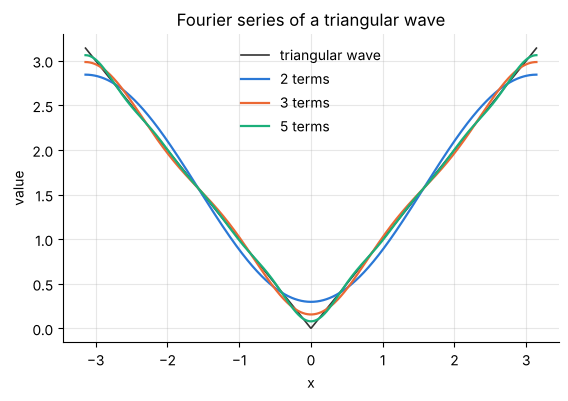

In [13]:
xs = np.linspace(-np.pi, np.pi, 1000)
fig, ax = plt.subplots()
ax.plot(xs, np.abs(xs), color="0.2", lw=1.2, label="triangular wave")
for terms in (2, 3, 5):
    ax.plot(xs, sp.lambdify(x, triangle.truncate(terms), "numpy")(xs), lw=1.6, label=f"{terms} terms")
ax.set(xlabel="x", ylabel="value", title="Fourier series of a triangular wave")
ax.legend(frameon=False, loc="upper center");

# five terms (the mean and four cosines) are already within 0.1 of the wave everywhere
assert np.abs(sp.lambdify(x, triangle.truncate(5), "numpy")(xs) - np.abs(xs)).max() < 0.1

**Answer.** $|x| = \dfrac{\pi}{2} - \dfrac{4}{\pi}\left(\cos x + \dfrac{\cos 3x}{9} +
\dfrac{\cos 5x}{25} + \dots\right)$: odd harmonics with amplitudes $4/(\pi n^2)$, against
$4/(\pi n)$ for the square wave. The triangular wave is continuous and only its slope jumps, so it
needs far less high-frequency content than a wave that jumps itself. Its slope is the square
wave, and integrating $\sin nx$ divides each coefficient by $n$. A few terms already fit well and
there is no Gibbs overshoot.

## Exercise 5

Use the final value theorem to find the steady-state error of the PI-controlled loop of
exercise 3 to a unit ramp in the set point. (It is finite, $12/K_c$, for $K_c$ below the
ultimate gain of exercise 3. With the proportional controller of 7.7 the error grows without
bound.)

The error is $E(s) = \dfrac{R(s)}{1 + G_c(s)\,G_p(s)}$, and a unit ramp has $R(s) = 1/s^2$.

In [14]:
Gp = 1 / ((s + 1) * (s + 2) * (s + 3))
error_pi = 1 / (1 + Kc * (1 + 1 / (tau_I * s)) * Gp)      # transfer function from set point to error
error_p = 1 / (1 + Kc * Gp)

ramp = 1 / s**2
e_pi = sp.limit(s * error_pi * ramp, s, 0)                # final value theorem
e_p = sp.limit(s * error_p * ramp, s, 0)
e_pi, e_p

⎛12    ⎞
⎜───, ∞⎟
⎝K_c   ⎠

**Verify in the time domain.** The final value theorem only applies if the limit exists, so check
it by simulating both loops for $K_c = 10$, which is below both ultimate gains.
`scipy.signal.lsim` simulates a transfer function, given as numerator and denominator
coefficients, for an arbitrary input.

In [15]:
def coefficients(transfer_function):
    """Numerator and denominator coefficients as lists of floats, highest power first."""
    num, den = sp.fraction(sp.cancel(transfer_function))
    return [float(v) for v in sp.Poly(num, s).all_coeffs()], [float(v) for v in sp.Poly(den, s).all_coeffs()]

times = np.linspace(0, 200, 4001)
_, err_pi, _ = lsim(coefficients(error_pi.subs(Kc, 10)), U=times, T=times)      # input U = t is the unit ramp
_, err_p, _ = lsim(coefficients(error_p.subs(Kc, 10)), U=times, T=times)

assert sp.simplify(e_pi - 12 / Kc) == 0 and e_p == sp.oo
assert abs(err_pi[-1] - 12 / 10) < 1e-6                   # PI: settles at 12/K_c = 1.2
slope = (err_p[-1] - err_p[2000]) / (times[-1] - times[2000])
assert abs(slope - 6 / (6 + 10)) < 1e-6                   # P: grows steadily at 6/(6 + K_c) per unit time
print(f"PI: error at t = 200 is {err_pi[-1]:.4f}      P: error still growing at {slope:.4f} per unit time")

PI: error at t = 200 is 1.2000      P: error still growing at 0.3750 per unit time


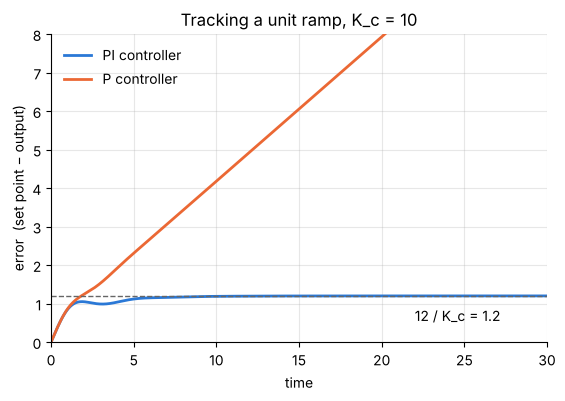

In [16]:
fig, ax = plt.subplots()
ax.plot(times, err_pi, label="PI controller")
ax.plot(times, err_p, label="P controller")
ax.axhline(1.2, color="0.4", lw=1, ls="--")
ax.annotate("12 / K_c = 1.2", xy=(22, 1.2), xytext=(22, 0.55))
ax.set(xlabel="time", ylabel="error  (set point − output)", xlim=(0, 30), ylim=(0, 8),
       title="Tracking a unit ramp, K_c = 10")
ax.legend(frameon=False, loc="upper left");

**Answer.** With the PI controller the steady-state error to a unit ramp is $12/K_c$
($= 6\tau_I/K_c$, where $1/6$ is the steady-state gain of the process), valid for gains below the
ultimate gain of exercise 3. One integrator in the loop turns an error that would grow into a
constant one. With the proportional controller the limit is infinite: the output settles to a
ramp of slope $K_c/(K_c+6)$, slower than the set point, so the error grows at the rate
$6/(6 + K_c)$ per unit time for ever.